# Experiment No. 5 (Computer Laboratory – I BE AI&DS)

**Aim:**  
Use different voting mechanisms and apply AdaBoost (Adaptive Boosting), Gradient Tree Boosting (GBM), and XGBoost classification on the Iris dataset, and compare the performance of the three models using different evaluation measures.

**Dataset Link:**  
`https://www.kaggle.com/datasets/uciml/iris` (Iris Species Dataset, 150 samples, 4 features).

**Objectives:**  
1. Load and preprocess the Iris dataset (features extraction and label encoding).
2. Implement and train individual boosting models: **AdaBoost**, **Gradient Tree Boosting (GBM)**, and **XGBoost**.
3. Implement ensemble voting mechanisms: **Hard Voting** (majority rule) and **Soft Voting** (predicted probability averaging).
4. Evaluate and compare all models across multiple metrics: **Accuracy**, **Precision**, **Recall**, and **F1-Score**.
5. Visualize the performance comparison using grouped bar charts and detailed classification report.

In [1]:
# Cell 1 - Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier, VotingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

from xgboost import XGBClassifier

In [2]:
# Cell 2 - Load and Inspect Dataset
url = "https://raw.githubusercontent.com/plotly/datasets/master/iris.csv"
df = pd.read_csv(url)

print("Dataset Shape:", df.shape)
print("\nFirst 5 Rows:")
print(df.head())

# Separate features and target
X = df.drop(columns=['Species', 'Name', 'Id'], errors='ignore')

y = df['Species'] if 'Species' in df.columns else df['Name']

# Convert categorical labels into numbers
le = LabelEncoder()
y = le.fit_transform(y)

print("\nClasses:", le.classes_)

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

Dataset Shape: (150, 5)

First 5 Rows:
   SepalLength  SepalWidth  PetalLength  PetalWidth         Name
0          5.1         3.5          1.4         0.2  Iris-setosa
1          4.9         3.0          1.4         0.2  Iris-setosa
2          4.7         3.2          1.3         0.2  Iris-setosa
3          4.6         3.1          1.5         0.2  Iris-setosa
4          5.0         3.6          1.4         0.2  Iris-setosa

Classes: ['Iris-setosa' 'Iris-versicolor' 'Iris-virginica']


In [3]:
# Cell 3 - Train Boosting Models

# AdaBoost
ada = AdaBoostClassifier(n_estimators=50, random_state=42)
ada.fit(X_train, y_train)
ada_pred = ada.predict(X_test)

# Gradient Boosting
gbm = GradientBoostingClassifier(n_estimators=50, random_state=42)
gbm.fit(X_train, y_train)
gbm_pred = gbm.predict(X_test)

# XGBoost
xgb = XGBClassifier(
    n_estimators=50,
    eval_metric='mlogloss',
    random_state=42
)
xgb.fit(X_train, y_train)
xgb_pred = xgb.predict(X_test)

In [4]:
# Cell 4 - Voting Classifier

# Hard Voting
hard_voting = VotingClassifier(
    estimators=[
        ('ada', AdaBoostClassifier(n_estimators=50, random_state=42)),
        ('gbm', GradientBoostingClassifier(n_estimators=50, random_state=42)),
        ('xgb', XGBClassifier(n_estimators=50, eval_metric='mlogloss', random_state=42))
    ],
    voting='hard'
)

hard_voting.fit(X_train, y_train)
hard_pred = hard_voting.predict(X_test)


# Soft Voting
soft_voting = VotingClassifier(
    estimators=[
        ('ada', AdaBoostClassifier(n_estimators=50, random_state=42)),
        ('gbm', GradientBoostingClassifier(n_estimators=50, random_state=42)),
        ('xgb', XGBClassifier(n_estimators=50, eval_metric='mlogloss', random_state=42))
    ],
    voting='soft'
)

soft_voting.fit(X_train, y_train)
soft_pred = soft_voting.predict(X_test)

In [5]:
# Cell 5 - Compare Model Performance

models = {
    'AdaBoost': ada_pred,
    'Gradient Boosting': gbm_pred,
    'XGBoost': xgb_pred,
    'Hard Voting': hard_pred,
    'Soft Voting': soft_pred
}

results = []

for name, predictions in models.items():
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions, average='weighted'),
        'Recall': recall_score(y_test, predictions, average='weighted'),
        'F1 Score': f1_score(y_test, predictions, average='weighted')
    })

comparison_df = pd.DataFrame(results)

print("\nModel Performance Comparison:")
print(comparison_df.round(4).to_string(index=False))


Model Performance Comparison:
            Model  Accuracy  Precision  Recall  F1 Score
         AdaBoost    0.9333     0.9333  0.9333    0.9333
Gradient Boosting    0.9667     0.9697  0.9667    0.9666
          XGBoost    0.9333     0.9333  0.9333    0.9333
      Hard Voting    0.9667     0.9697  0.9667    0.9666
      Soft Voting    0.9667     0.9697  0.9667    0.9666


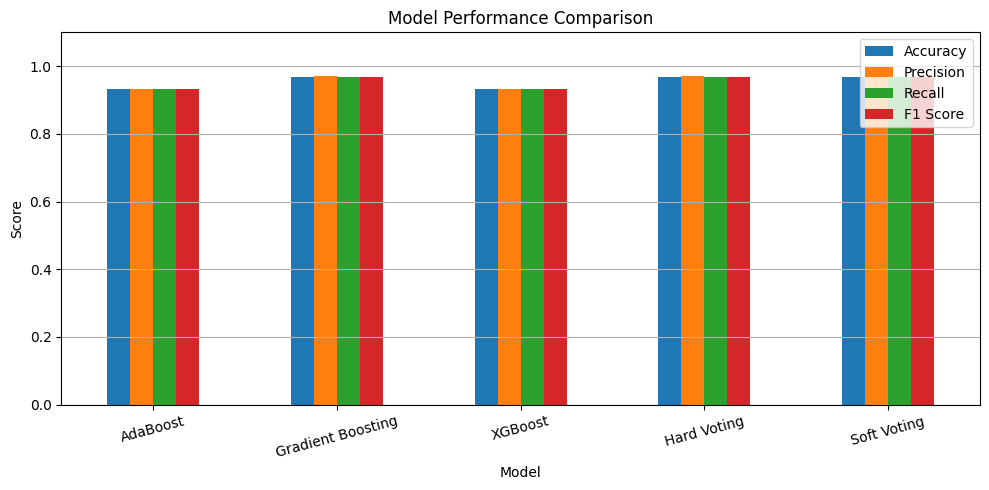

In [6]:
# Cell 6 - Visualize Model Performance

comparison_df.set_index('Model').plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.1)
plt.xticks(rotation=15)
plt.grid(axis='y')
plt.legend()
plt.tight_layout()
plt.show()

In [7]:
# Cell 7 - Classification Report

print("\nClassification Report - Soft Voting:")
print(classification_report(
    y_test,
    soft_pred,
    target_names=le.classes_
))


Classification Report - Soft Voting:
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       1.00      0.90      0.95        10
 Iris-virginica       0.91      1.00      0.95        10

       accuracy                           0.97        30
      macro avg       0.97      0.97      0.97        30
   weighted avg       0.97      0.97      0.97        30

